# Seasonal Agriculture Performance Analysis

**VOIS AICTE Batch 1, 2026–2027 | Major Project**

### Project objective
Analyze agricultural data across **Kharif, Rabi and Zaid** seasons to identify meaningful patterns, trends, relationships and variations in agricultural performance.

The analysis follows the project brief: dataset exploration, cleaning, seasonal comparison, relationship analysis, statistical techniques, visualization, evidence-based findings and recommendations.

## 1. Problem Statement

Agricultural activities are influenced by seasonal variations in environmental conditions, farming practices, resource availability and market conditions. Raw agricultural data does not directly explain how performance changes across seasons.

This project therefore investigates seasonal differences in agricultural performance by examining patterns, trends, relationships and variations in the available data.

## 2. Analytical Questions

1. How does agricultural performance vary across seasons?
2. What seasonal patterns are visible in yield, profit and revenue?
3. How do rainfall and temperature differ between seasons?
4. How does irrigation method relate to seasonal performance?
5. Which crop-season combinations show notable profit differences?
6. What variables are associated with yield and profit?
7. Are the observed seasonal differences statistically distinguishable?
8. What evidence-based insights can support seasonal agricultural planning?

In [3]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 3. Load Dataset

In [1]:
from pathlib import Path
import pandas as pd

csv_name = "seasonal_agriculture_performance_dataset.csv"
candidates = [
    Path.cwd() / csv_name,
    Path(r"C:\Users\SHUBHAM\OneDrive\Desktop\Shudh Swad") / csv_name,
]

data_path = next((path for path in candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        f"Dataset not found. Checked: {', '.join(str(path) for path in candidates)}"
    )

df = pd.read_csv(data_path)
print(f"Dataset path: {data_path.resolve()}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

C:\Users\SHUBHAM\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Dataset path: C:\Users\SHUBHAM\OneDrive\Desktop\Shudh Swad\seasonal_agriculture_performance_dataset.csv
Rows: 4,000
Columns: 28


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


## 4. Dataset Structure and Data Quality

In [3]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = missing["missing_count"] / len(df) * 100
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (4000, 28)

Data types:


,dtype
Farm_ID,object
State,object
District,object
Crop,object
Season,object
Farm_Area_Hectares,float64
Rainfall_mm,float64
Avg_Temperature_C,float64
Humidity_pct,float64
Sunlight_Hours_Day,float64



Missing values:


,missing_count,missing_pct
Rainfall_mm,48,1.20
Soil_Moisture_pct,40,1.00
Yield_Tonnes_Ha,32,0.80



Duplicate rows: 0


### Data cleaning decision

The dataset contains a small number of missing values in `Rainfall_mm`, `Soil_Moisture_pct` and `Yield_Tonnes_Ha`. Because these are continuous numeric measures, the missing values are imputed with their respective **medians** to reduce the influence of skewed values and retain the observations.

No duplicate rows were found in the supplied dataset.

In [4]:
clean_df = df.copy()

for col in ["Rainfall_mm", "Soil_Moisture_pct", "Yield_Tonnes_Ha"]:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

clean_df["Profit_Margin_pct"] = np.where(
    clean_df["Revenue_INR"] != 0,
    clean_df["Profit_INR"] / clean_df["Revenue_INR"] * 100,
    np.nan
)
clean_df["Cost_per_Tonne_INR"] = np.where(
    clean_df["Production_Tonnes"] != 0,
    clean_df["Total_Cost_INR"] / clean_df["Production_Tonnes"],
    np.nan
)
clean_df["Positive_Profit"] = clean_df["Profit_INR"] > 0

print("Missing values after cleaning:", int(clean_df.isna().sum().sum()))
clean_df.head()

Missing values after cleaning: 0


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct,Profit_Margin_pct,Cost_per_Tonne_INR,Positive_Profit
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.40,24.30,69.10,5.80,7.14,32.80,75.80,61.30,91.00,Drip,242.70,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.49,55.30,-38.47,"32,816.92",False
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.40,25.70,78.40,5.10,5.20,32.00,82.10,35.40,121.80,Flood,271.40,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.40,49.90,"-1,118.66","251,199.49",False
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.60,23.90,56.40,10.30,5.82,8.10,118.50,51.50,117.90,Drip,162.60,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.98,33.70,-65.49,"124,588.93",False
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.20,29.70,65.20,6.30,5.98,23.70,138.60,55.60,115.50,Rainfed,182.20,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.16,50.60,-47.68,"35,802.42",False
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.60,34.10,55.20,6.50,6.90,29.30,124.10,69.00,121.40,Flood,244.90,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.83,32.30,-74.56,"36,339.68",False


## 5. Exploratory Data Analysis

In [5]:
print("Season distribution:")
display(clean_df["Season"].value_counts().to_frame("farms"))

print("Crop distribution:")
display(clean_df["Crop"].value_counts().to_frame("farms"))

print("Irrigation methods:")
display(clean_df["Irrigation_Method"].value_counts().to_frame("farms"))

print("States:", clean_df["State"].nunique())
display(clean_df["State"].value_counts().to_frame("farms"))

Season distribution:


,farms
Season,
Kharif,1779
Rabi,1627
Zaid,594


Crop distribution:


,farms
Crop,
Rice,690
Wheat,614
Maize,551
Cotton,508
Pulses,496
Groundnut,424
Chilli,412
Sugarcane,305


Irrigation methods:


,farms
Irrigation_Method,
Flood,1310
Rainfed,1041
Drip,915
Sprinkler,734


States: 8


,farms
State,
Andhra Pradesh,529
Telangana,516
Maharashtra,512
Madhya Pradesh,497
Karnataka,489
Gujarat,488
Tamil Nadu,485
Punjab,484


## 6. Seasonal Performance Summary

In [6]:
season_order = ["Kharif", "Rabi", "Zaid"]

season_summary = clean_df.groupby("Season").agg(
    Farms=("Farm_ID", "count"),
    Avg_Yield_Tonnes_Ha=("Yield_Tonnes_Ha", "mean"),
    Median_Yield_Tonnes_Ha=("Yield_Tonnes_Ha", "median"),
    Avg_Profit_INR=("Profit_INR", "mean"),
    Median_Profit_INR=("Profit_INR", "median"),
    Avg_Revenue_INR=("Revenue_INR", "mean"),
    Avg_Cost_INR=("Total_Cost_INR", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Avg_Disease_Risk_pct=("Disease_Pest_Risk_pct", "mean"),
    Avg_Rainfall_mm=("Rainfall_mm", "mean"),
    Avg_Temperature_C=("Avg_Temperature_C", "mean"),
    Avg_Water_Used_m3=("Water_Used_m3", "mean"),
    Positive_Profit_Rate=("Positive_Profit", "mean")
).reindex(season_order)

display(season_summary)

,Farms,Avg_Yield_Tonnes_Ha,Median_Yield_Tonnes_Ha,Avg_Profit_INR,Median_Profit_INR,Avg_Revenue_INR,Avg_Cost_INR,Avg_Water_Efficiency,Avg_Disease_Risk_pct,Avg_Rainfall_mm,Avg_Temperature_C,Avg_Water_Used_m3,Positive_Profit_Rate
Season,,,,,,,,,,,,,
Kharif,1779,5.63,1.94,"178,914.65","38,808.00","710,719.06","531,804.41",5.89,54.47,849.20,28.45,"6,102.20",0.58
Rabi,1627,5.04,1.67,"87,689.47","-3,187.00","601,526.05","513,836.58",5.19,40.48,437.62,23.49,"5,846.99",0.49
Zaid,594,4.64,1.46,"-24,804.82","-62,144.00","519,171.90","543,976.73",4.41,38.22,304.65,31.04,"6,419.89",0.36


### Finding: seasonal profit

In [7]:
season_summary["Positive_Profit_Rate_pct"] = season_summary["Positive_Profit_Rate"] * 100
display(
    season_summary[
        ["Avg_Profit_INR", "Median_Profit_INR", "Positive_Profit_Rate_pct",
         "Avg_Yield_Tonnes_Ha", "Avg_Water_Efficiency"]
    ].round(2)
)

,Avg_Profit_INR,Median_Profit_INR,Positive_Profit_Rate_pct,Avg_Yield_Tonnes_Ha,Avg_Water_Efficiency
Season,,,,,
Kharif,"178,914.65","38,808.00",57.79,5.63,5.89
Rabi,"87,689.47","-3,187.00",48.86,5.04,5.19
Zaid,"-24,804.82","-62,144.00",35.52,4.64,4.41


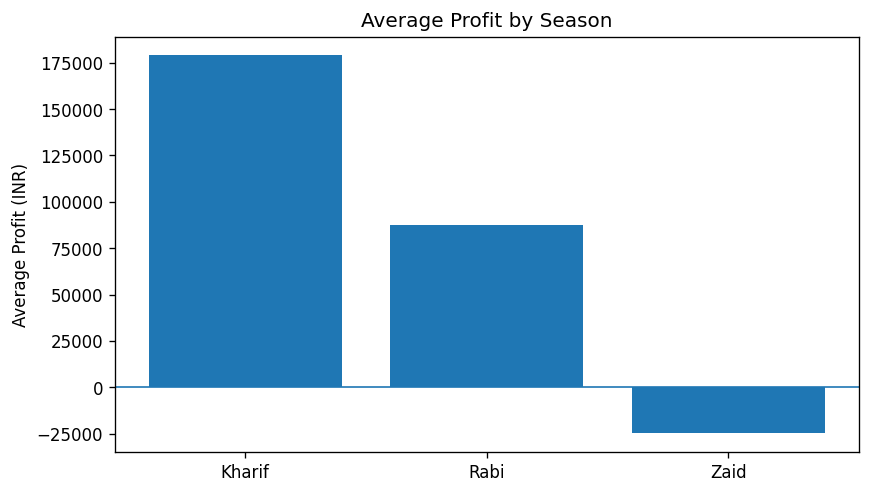

In [8]:
plt.figure(figsize=(8, 4.5))
plt.bar(season_summary.index, season_summary["Avg_Profit_INR"])
plt.axhline(0, linewidth=1)
plt.title("Average Profit by Season")
plt.ylabel("Average Profit (INR)")
plt.show()

### Finding: yield

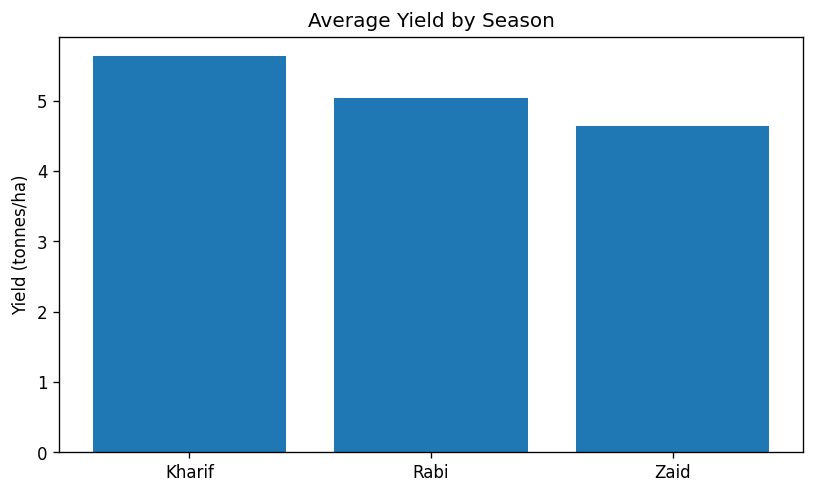

In [9]:
plt.figure(figsize=(8, 4.5))
plt.bar(season_summary.index, season_summary["Avg_Yield_Tonnes_Ha"])
plt.title("Average Yield by Season")
plt.ylabel("Yield (tonnes/ha)")
plt.show()

## 7. Profit Distribution and Seasonal Variability

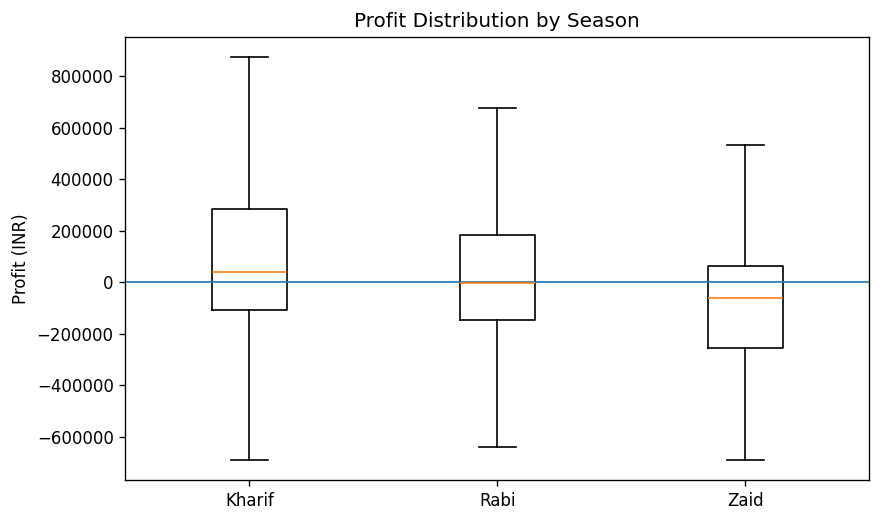

In [10]:
plt.figure(figsize=(8, 4.8))
plt.boxplot(
    [clean_df.loc[clean_df["Season"] == s, "Profit_INR"].dropna() for s in season_order],
    labels=season_order,
    showfliers=False
)
plt.axhline(0, linewidth=1)
plt.title("Profit Distribution by Season")
plt.ylabel("Profit (INR)")
plt.show()

The profit distribution is highly variable. Median profit is substantially lower than the mean in all seasons, indicating that a smaller number of high-profit observations pull the mean upward. Therefore, both mean and median should be considered when interpreting seasonal profitability.

## 8. Environmental Conditions by Season

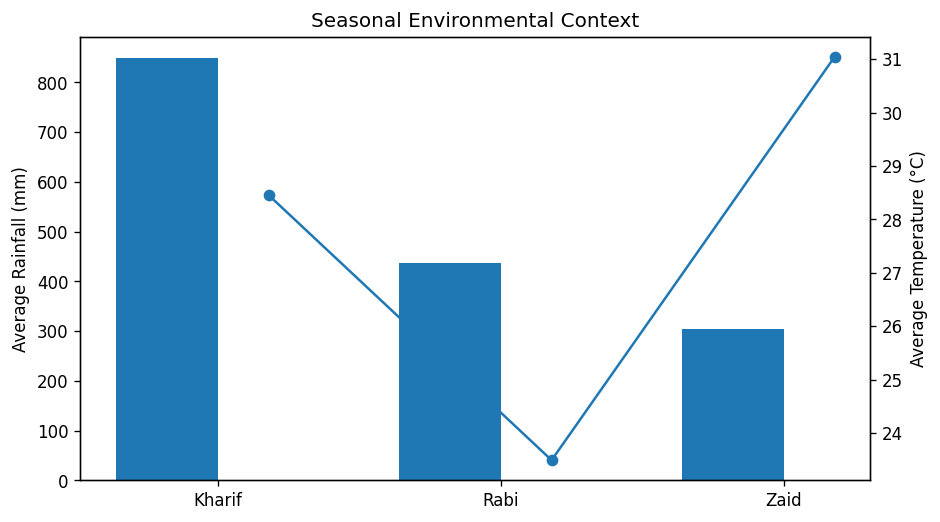

In [11]:
x = np.arange(len(season_order))
width = 0.36

fig, ax1 = plt.subplots(figsize=(8.5, 4.8))
ax1.bar(x - width/2, season_summary["Avg_Rainfall_mm"], width, label="Rainfall (mm)")
ax1.set_ylabel("Average Rainfall (mm)")
ax1.set_xticks(x)
ax1.set_xticklabels(season_order)

ax2 = ax1.twinx()
ax2.plot(x + width/2, season_summary["Avg_Temperature_C"], marker="o", label="Temperature (°C)")
ax2.set_ylabel("Average Temperature (°C)")

plt.title("Seasonal Environmental Context")
plt.show()

## 9. Irrigation Analysis

,Season,Irrigation_Method,Avg_Profit,Avg_Yield,Avg_Water_Efficiency,Farms
0,Kharif,Drip,"317,222.07",7.26,6.80,405
1,Kharif,Flood,"133,373.83",4.98,3.64,590
2,Kharif,Rainfed,"158,974.13",5.70,8.85,463
3,Kharif,Sprinkler,"116,880.49",4.66,4.62,321
4,Rabi,Drip,"187,843.22",6.11,6.05,370
5,Rabi,Flood,"58,824.80",5.06,3.48,526
6,Rabi,Rainfed,"45,232.48",3.93,6.87,438
7,Rabi,Sprinkler,"76,502.07",5.31,4.64,293
8,Zaid,Drip,"21,291.84",5.85,5.30,140
9,Zaid,Flood,"-69,786.78",3.98,2.73,194


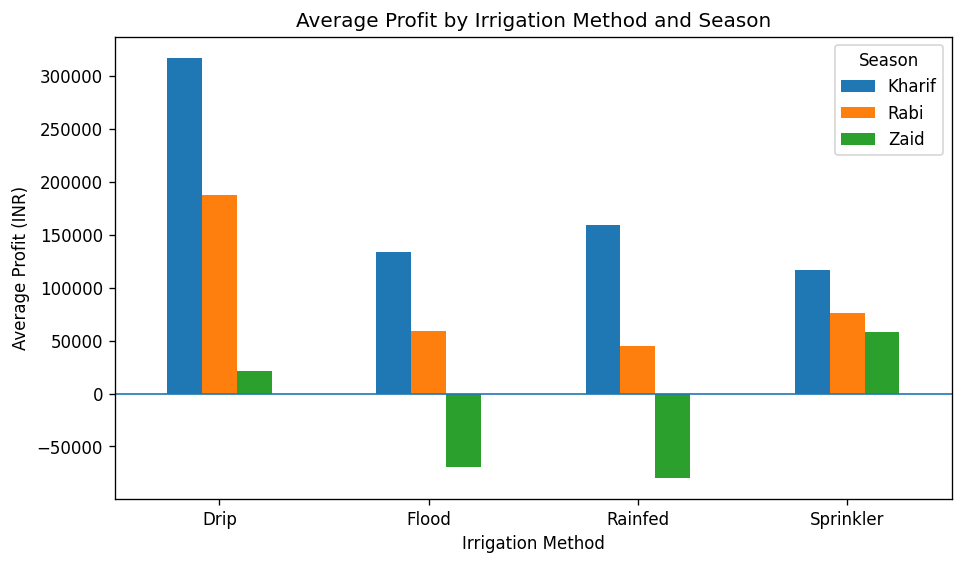

In [12]:
irrigation_season = clean_df.groupby(["Season", "Irrigation_Method"]).agg(
    Avg_Profit=("Profit_INR", "mean"),
    Avg_Yield=("Yield_Tonnes_Ha", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Farms=("Farm_ID", "count")
).reset_index()

display(irrigation_season.round(2))

pivot_irrig = irrigation_season.pivot(
    index="Irrigation_Method", columns="Season", values="Avg_Profit"
).reindex(columns=season_order)

ax = pivot_irrig.plot(kind="bar", figsize=(9, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Average Profit by Irrigation Method and Season")
ax.set_xlabel("Irrigation Method")
ax.set_ylabel("Average Profit (INR)")
plt.xticks(rotation=0)
plt.show()

## 10. Crop × Season Analysis

,Season,Crop,Avg_Yield,Avg_Profit,Farms
6,Kharif,Sugarcane,53.46,"1,000,790.81",125
0,Kharif,Chilli,1.73,"954,380.42",185
14,Rabi,Sugarcane,43.29,"731,612.86",129
8,Rabi,Chilli,1.47,"638,572.50",163
22,Zaid,Sugarcane,38.42,"583,635.80",51
16,Zaid,Chilli,1.20,"448,659.09",64
1,Kharif,Cotton,1.37,"216,999.55",215
2,Kharif,Groundnut,1.48,"108,265.44",193
9,Rabi,Cotton,1.20,"107,343.59",201
4,Kharif,Pulses,1.04,"43,338.90",221


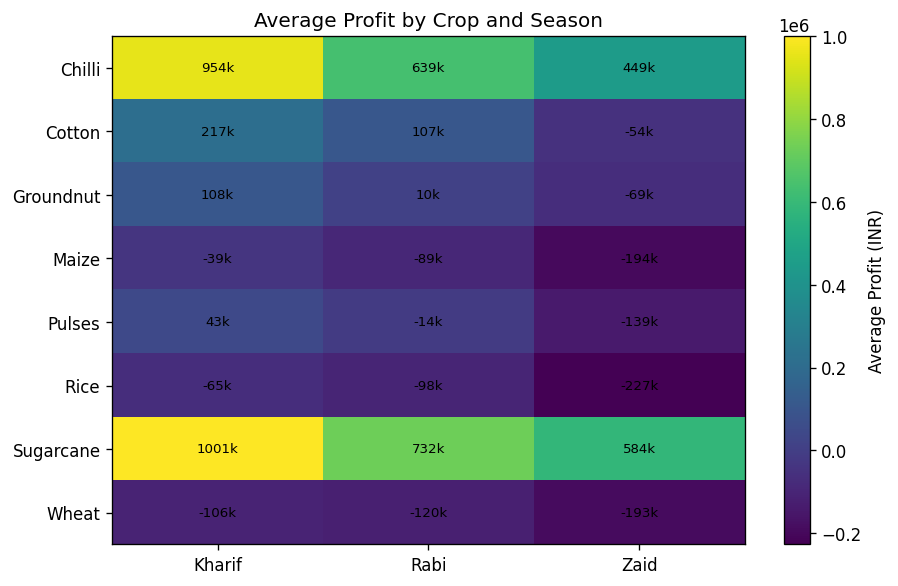

In [13]:
crop_season = clean_df.groupby(["Season", "Crop"]).agg(
    Avg_Yield=("Yield_Tonnes_Ha", "mean"),
    Avg_Profit=("Profit_INR", "mean"),
    Farms=("Farm_ID", "count")
).reset_index()

display(crop_season.sort_values("Avg_Profit", ascending=False).head(10).round(2))

pivot_crop = crop_season.pivot(index="Crop", columns="Season", values="Avg_Profit").reindex(columns=season_order)

plt.figure(figsize=(8.5, 5.5))
plt.imshow(pivot_crop.values, aspect="auto")
plt.colorbar(label="Average Profit (INR)")
plt.xticks(range(len(season_order)), season_order)
plt.yticks(range(len(pivot_crop.index)), pivot_crop.index)
plt.title("Average Profit by Crop and Season")
for i in range(pivot_crop.shape[0]):
    for j in range(pivot_crop.shape[1]):
        plt.text(j, i, f"{pivot_crop.iloc[i, j]/1000:.0f}k", ha="center", va="center", fontsize=8)
plt.show()

## 11. Correlation and Relationship Analysis

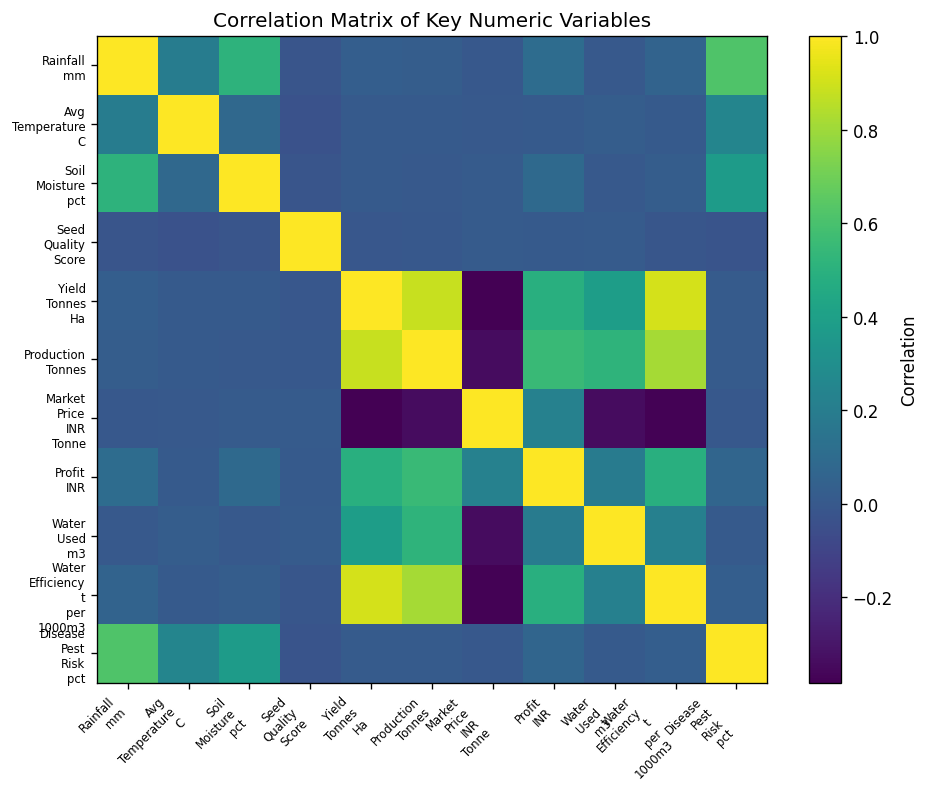

Variables most positively correlated with Profit_INR:


,correlation
Profit_INR,1.00
Production_Tonnes,0.55
Water_Efficiency_t_per_1000m3,0.49
Yield_Tonnes_Ha,0.49
Market_Price_INR_Tonne,0.23
Water_Used_m3,0.19
Rainfall_mm,0.11
Soil_Moisture_pct,0.09


Variables most positively correlated with Yield_Tonnes_Ha:


,correlation
Yield_Tonnes_Ha,1.00
Water_Efficiency_t_per_1000m3,0.91
Production_Tonnes,0.88
Profit_INR,0.49
Water_Used_m3,0.39
Rainfall_mm,0.03
Disease_Pest_Risk_pct,0.01
Soil_Moisture_pct,0.01


In [14]:
corr_cols = [
    "Rainfall_mm", "Avg_Temperature_C", "Soil_Moisture_pct",
    "Seed_Quality_Score", "Yield_Tonnes_Ha", "Production_Tonnes",
    "Market_Price_INR_Tonne", "Profit_INR", "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3", "Disease_Pest_Risk_pct"
]

corr = clean_df[corr_cols].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr.values, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_cols)), [c.replace("_", "\n") for c in corr_cols], rotation=45, ha="right", fontsize=7)
plt.yticks(range(len(corr_cols)), [c.replace("_", "\n") for c in corr_cols], fontsize=7)
plt.title("Correlation Matrix of Key Numeric Variables")
plt.show()

print("Variables most positively correlated with Profit_INR:")
display(corr["Profit_INR"].sort_values(ascending=False).head(8).to_frame("correlation"))

print("Variables most positively correlated with Yield_Tonnes_Ha:")
display(corr["Yield_Tonnes_Ha"].sort_values(ascending=False).head(8).to_frame("correlation"))

### Interpretation

The strongest observed relationships include:

- **Yield and water efficiency**: strong positive association.
- **Yield and production**: strong positive association.
- **Revenue and profit**: strong positive association.
- **Yield and profit**: moderate positive association.
- **Market price and yield**: negative association in this dataset.

Correlation measures association, not causation. These relationships should therefore be treated as analytical signals rather than causal effects.

## 12. Statistical Test: Seasonal Differences

In [15]:
profit_groups = [
    clean_df.loc[clean_df["Season"] == s, "Profit_INR"].dropna()
    for s in season_order
]
yield_groups = [
    clean_df.loc[clean_df["Season"] == s, "Yield_Tonnes_Ha"].dropna()
    for s in season_order
]

kw_profit = stats.kruskal(*profit_groups)
kw_yield = stats.kruskal(*yield_groups)

print("Kruskal-Wallis test for Profit:")
print(f"Statistic = {kw_profit.statistic:.3f}, p-value = {kw_profit.pvalue:.3e}")

print("\nKruskal-Wallis test for Yield:")
print(f"Statistic = {kw_yield.statistic:.3f}, p-value = {kw_yield.pvalue:.3e}")

Kruskal-Wallis test for Profit:
Statistic = 101.926, p-value = 7.363e-23

Kruskal-Wallis test for Yield:
Statistic = 68.713, p-value = 1.200e-15


### Statistical interpretation

The Kruskal-Wallis test is appropriate here as a rank-based test that does not require normally distributed observations. For this dataset, the test results indicate statistically detectable differences in the distributions of both **profit** and **yield** across seasons at conventional significance levels.

Statistical significance does not by itself establish causation or practical importance. The effect should be interpreted together with the descriptive statistics and visualizations.

## 13. Water Efficiency and Positive Profit Rate

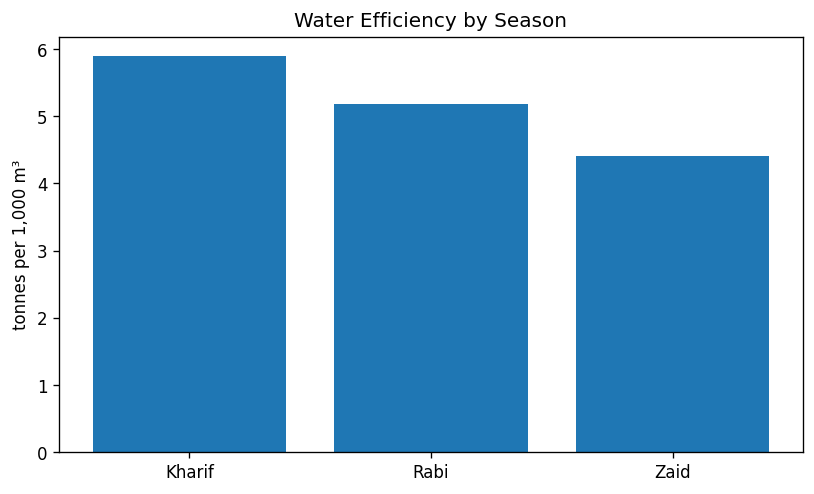

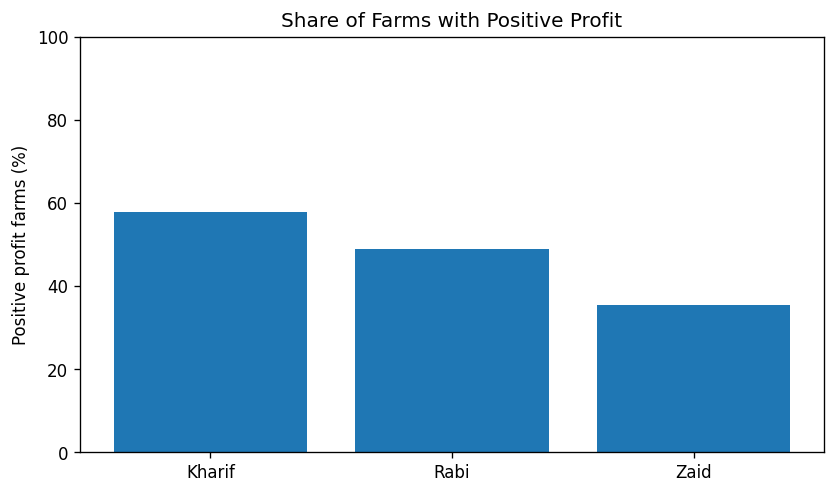

In [16]:
plt.figure(figsize=(8, 4.5))
plt.bar(season_summary.index, season_summary["Avg_Water_Efficiency"])
plt.title("Water Efficiency by Season")
plt.ylabel("tonnes per 1,000 m³")
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(season_summary.index, season_summary["Positive_Profit_Rate"] * 100)
plt.title("Share of Farms with Positive Profit")
plt.ylabel("Positive profit farms (%)")
plt.ylim(0, 100)
plt.show()

## 14. Key Findings

## 14. Key Findings

1. **Kharif has the highest average profit** in the supplied dataset at approximately **₹178,915 per farm**, while Zaid has an average loss of approximately **₹24,805**.
2. Kharif also has the highest average yield at approximately **5.63 tonnes/ha**.
3. The share of farms with positive profit is approximately **57.8% in Kharif**, **48.9% in Rabi**, and **35.5% in Zaid**.
4. Average water efficiency is highest in Kharif and lowest in Zaid.
5. Profit varies considerably within every season, so seasonal averages should not be interpreted as applying equally to every farm.
6. Crop and irrigation method create additional differences within seasons, indicating that season alone does not explain all performance variation.

## 15. Data-Driven Recommendations

- Use seasonal performance summaries to support crop and resource planning.
- Treat irrigation method as an important comparison dimension rather than analyzing seasons in isolation.
- Monitor profitability using both mean and median values because the profit distribution is highly variable.
- Track water efficiency together with yield to evaluate resource use.
- Investigate crop-season combinations with unusually high or low profitability before making operational decisions.
- For a production system, combine historical records with local weather, soil and market data before making farm-level recommendations.

## 16. Limitations and Future Scope

### Limitations
- The analysis is based only on the supplied dataset.
- Correlations describe associations and do not prove causal relationships.
- Missing continuous values were median-imputed.
- The dataset contains multiple geographic and crop categories, so subgroup context matters.

### Future scope
- Build an interactive dashboard using Power BI, Tableau or Plotly Dash.
- Add time-series forecasting when multi-year temporal data are available.
- Develop predictive models for yield or profitability.
- Integrate weather and market-price feeds.
- Add geospatial analysis using farm or district coordinates.
- Create anomaly alerts for unusual yield, cost, risk or water-efficiency observations.

## 17. Conclusion

The analysis converts the supplied agricultural dataset into a structured seasonal view of performance. The results show meaningful differences in profitability, yield distributions, environmental conditions, water efficiency and within-season performance across crops and irrigation methods. These findings can support evidence-based seasonal agricultural planning while recognizing that the dataset alone cannot establish causal relationships.